In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

TARGET = "Machine failure"
FEATURES = ["Torque [Nm]", "Type", "Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Tool wear [min]"]
df = pd.read_csv("data/ai4i2020.csv")
df2 = pd.read_csv("data/taxi_2025_01_cours.csv")

In [2]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.shape

(10000, 14)

In [4]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [6]:
df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [7]:
df.head(30)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


In [8]:
df["Machine failure"].mean()

np.float64(0.0339)

In [9]:
df["Machine failure"].sum()

np.int64(339)

In [10]:
df.groupby("Type")["Machine failure"].mean()

Type
H    0.020937
L    0.039167
M    0.027694
Name: Machine failure, dtype: float64

In [11]:
df.groupby("Type")["Machine failure"].agg(["count", "sum", "mean"])

,count,sum,mean
Type,,,
H,1003,21,0.020937
L,6000,235,0.039167
M,2997,83,0.027694


In [12]:
taux = df.groupby("Type")["Machine failure"].mean() * 100

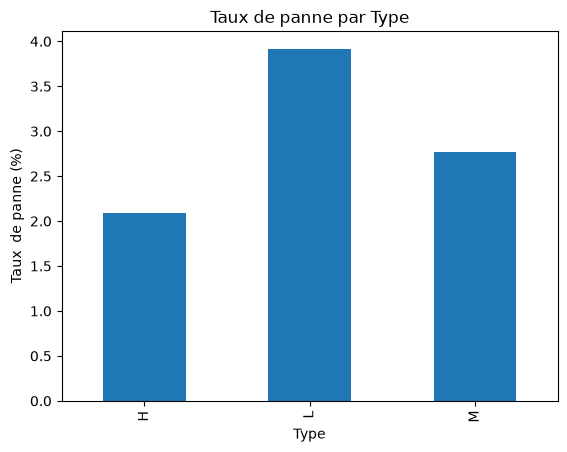

In [13]:
taux.plot(kind="bar")
plt.ylabel("Taux  de panne (%)")
plt.title("Taux de panne par Type")
plt.show()

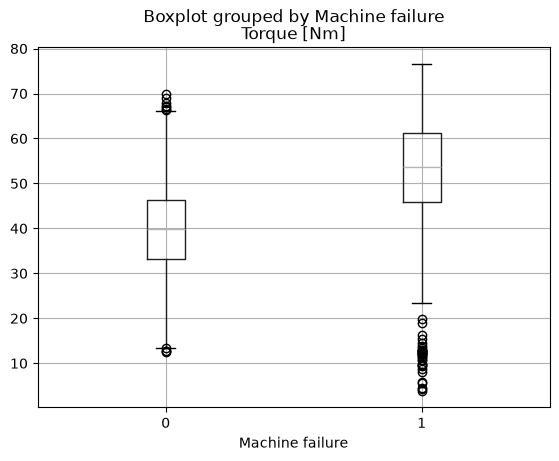

In [14]:
df.boxplot(column="Torque [Nm]", by="Machine failure")
plt.show()

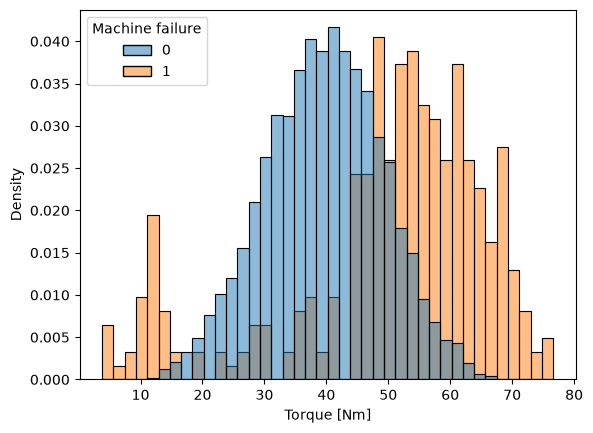

In [15]:
import seaborn as sns
sns.histplot(data=df, x="Torque [Nm]", hue="Machine failure", stat="density", common_norm=False, bins=40)
plt.show()

In [16]:
X = df[FEATURES]
Y = df[TARGET]

In [17]:
print(X.shape, Y.shape)
print(type(X), type(Y))

(10000, 6) (10000,)
<class 'pandas.DataFrame'> <class 'pandas.Series'>


In [18]:
X_train, X_tmp, Y_train, Y_tmp = train_test_split(X, Y, test_size=0.4, stratify=Y, random_state=42)

In [19]:
X_val, X_test, Y_val, Y_test = train_test_split(X_tmp, Y_tmp, test_size=0.5, stratify=Y_tmp, random_state=42)

In [20]:
print(len(X_train), len(X_val), len(X_test))
print(Y_train.mean(), Y_val.mean(), Y_test.mean())


6000 2000 2000
0.03383333333333333 0.034 0.034


In [21]:
X_train.describe()

,Torque [Nm],Air temperature [K],Process temperature [K],Rotational speed [rpm],Tool wear [min]
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,40.034067,300.019783,310.012383,1538.869500,107.492833
std,10.035769,2.004329,1.479536,180.530086,63.571628
min,3.800000,295.300000,305.700000,1168.000000,0.000000
25%,33.200000,298.300000,308.800000,1422.000000,52.000000
50%,40.100000,300.100000,310.100000,1503.000000,107.000000
75%,46.900000,301.500000,311.100000,1614.000000,162.000000
max,76.600000,304.500000,313.800000,2886.000000,253.000000


In [22]:
NUM_COLS = ["Torque [Nm]", "Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Tool wear [min]"]
CAT_COLS = ["Type"]

In [23]:
preprocess = ColumnTransformer([("num", StandardScaler(), NUM_COLS), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS)])

In [24]:
X_train_p = preprocess.fit_transform(X_train)
X_val_p = preprocess.transform(X_val)
X_test_p = preprocess.transform(X_test)


In [25]:
print(X_train_p.shape, X_val_p.shape, X_test_p.shape)
print(preprocess.get_feature_names_out())

(6000, 8) (2000, 8) (2000, 8)
['num__Torque [Nm]' 'num__Air temperature [K]'
 'num__Process temperature [K]' 'num__Rotational speed [rpm]'
 'num__Tool wear [min]' 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


In [26]:
scaler = preprocess.named_transformers_["num"]
print(scaler.mean_)
print(scaler.scale_)

[  40.03406667  300.01978333  310.01238333 1538.8695      107.49283333]
[ 10.03493246   2.00416241   1.4794126  180.5150413   63.56632978]


In [27]:
encoder = preprocess.named_transformers_["cat"]
print(encoder.categories_)

[array(['H', 'L', 'M'], dtype=object)]


In [28]:
print(X_train_p[:, :5].mean(axis=0).round(3))
print(X_val_p[:, :5].mean(axis=0).round(3))
print(X_test_p[:, :5].mean(axis=0).round(3))

[ 0. -0.  0. -0. -0.]
[-0.012 -0.029 -0.024 -0.002  0.004]
[-0.011 -0.008  0.001 -0.001  0.032]


In [29]:
df2.columns

Index(['PULocationID', 'pickup', 'duration_min', 'hour', 'weekday'], dtype='str')

In [30]:
df2.head(20)

,PULocationID,pickup,duration_min,hour,weekday
0,75,2025-01-01 00:03:01,14.183333,0,2
1,41,2025-01-01 00:05:19,5.766667,0,2
2,256,2025-01-01 00:11:53,7.483333,0,2
3,166,2025-01-01 00:19:59,5.883333,0,2
4,82,2025-01-01 00:22:24,4.233333,0,2
5,168,2025-01-01 00:22:29,3.500000,0,2
6,255,2025-01-01 00:24:37,25.866667,0,2
7,236,2025-01-01 00:24:44,9.216667,0,2
8,66,2025-01-01 00:25:05,36.083333,0,2
9,41,2025-01-01 00:25:23,10.300000,0,2


In [31]:
df2.dtypes

PULocationID      int64
pickup              str
duration_min    float64
hour              int64
weekday           int64
dtype: object

In [32]:
train = df2[df2["pickup"] < "2025-01-20"]

In [33]:
val = df2[(df2["pickup"] < "2025-01-26") & (df2["pickup"] >= "2025-01-20")] 

In [34]:
test = df2[(df2["pickup"] < "2025-02-01") & (df2["pickup"] >= "2025-01-26")] 

In [35]:
print(len(train), len(val), len(test))
print(len(train) + len(val) + len(test))
print(train["pickup"].min(), train ["pickup"].max())
print(val["pickup"].min(), val ["pickup"].max())
print(test["pickup"].min(), test ["pickup"].max())

11782 4009 4209
20000
2025-01-01 00:03:01 2025-01-19 23:58:37
2025-01-20 00:09:13 2025-01-25 23:58:58
2025-01-26 00:01:46 2025-01-31 23:54:07


In [36]:
FEATURES2 = ["PULocationID", "hour", "weekday"]
TARGET2 = "duration_min"

In [37]:
X_train2, y_train2 = train[FEATURES2], train[TARGET2]
X_val2, y_val2 = val[FEATURES2], val[TARGET2]

In [38]:
base = DummyRegressor(strategy="median")
base.fit(X_train2, y_train2)
pred_base = base.predict(X_val2)
mae_base = mean_absolute_error(y_val2, pred_base)
print(mae_base)

6.263735761203957


In [39]:
prep2 = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FEATURES2)])

In [40]:
model = make_pipeline(prep2, Ridge(alpha=1.0, solver="lsqr"))
model.fit(X_train2, y_train2)
pred_ridge = model.predict(X_val2)
mae_ridge = mean_absolute_error(y_val2, pred_ridge)
print(mae_ridge)

6.438622380310614


In [41]:
residuals = y_val2 - pred_ridge

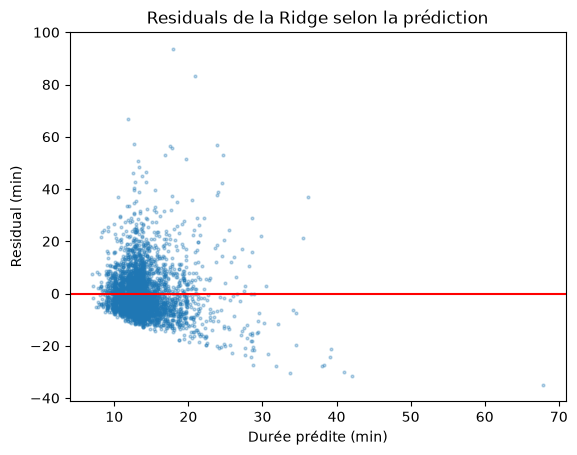

In [42]:
plt.scatter(pred_ridge, residuals, s=4, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Durée prédite (min)")
plt.ylabel("Residual (min)")
plt.title("Residuals de la Ridge selon la prédiction")
plt.show()

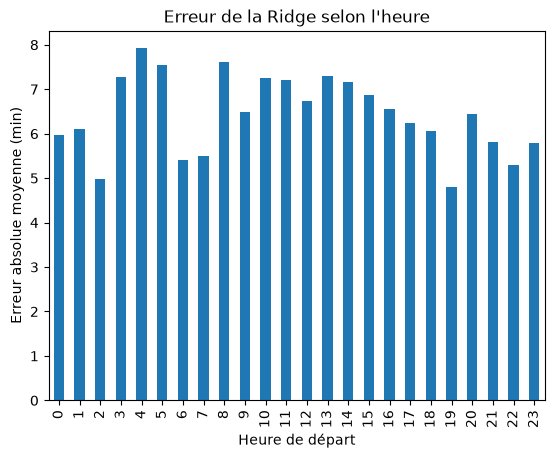

In [43]:
erreur_par_heure = residuals.abs().groupby(X_val2["hour"]).mean()
erreur_par_heure.plot(kind="bar")
plt.xlabel("Heure de départ")
plt.ylabel("Erreur absolue moyenne (min)")
plt.title("Erreur de la Ridge selon l'heure")
plt.show()